# **How to Run MegaDetector: A Practical Workflow**

The MegaDetector was employed to automatically eliminate blank images from the camera trap dataset. Since MegaDetector only performs animal detection without providing species-level identification, a custom YOLO11 model was integrated, specifically trained for species classification. This workflow enables the combination of both approaches: efficient blank image removal with MegaDetector and accurate species identification with YOLO11.

The description of MegaDetector’s functionality was based on the official documentation available at
[MegaDetector](https://github.com/agentmorris/MegaDetector/tree/main)

In [ ]:
#Required libraries
!pip install humanfriendly jsonpickle ultralytics

##Required resources

In [ ]:
!rm -rf /content/MegaDetector
!rm -rf /content/yolov5
!git clone https://github.com/ecologize/yolov5/ /content/yolov5
!git clone https://github.com/agentmorris/MegaDetector /content/MegaDetector

##Environment variables

In [ ]:
import os
os.environ['PYTHONPATH'] += ":/content/MegaDetector"
os.environ['PYTHONPATH'] += ":/content/yolov5"

## Run the detection script

The run_detector_batch.py script requires three mandatory arguments:

1.   MegaDetector model file (either a model name, e.g., "MDV5A", or a path to a model file).
2.   Image folder (directory containing the images to be processed).
3.   Output JSON file location and name.




In [ ]:
#Script for batch image processing
!python /content/MegaDetector/megadetector/detection/run_detector_batch.py "MDV5A" "/content/img" "/content/teste.json" --threshold 0.5

In [ ]:
#Script for single-image processing
!python /content/MegaDetector/megadetector/detection/run_detector.py "MDV5" --image_file "image_file" --threshold 0.70 --output_dir "/content/teste"

The process_video.py script from MegaDetector requires two mandatory arguments:


1.   Model file (model_file) – this can be either a model name (e.g., "MDV5A") or the path to a MegaDetector model file (.pt or .pb). You can also use "no_detection" if you only want to extract video frames without running detection.

1.   Input video file (input_video_file) – the video (or folder of videos) to be processed.




In [ ]:
!python /content/MegaDetector/megadetector/detection/process_video.py "MDV5A" "input_video_file or input_videos_folder" --output_json_file "/content/teste/test_output.json" --json_confidence_threshold 0.5

# Visualization

In [ ]:
import cv2
import os

In [ ]:
# Annotate images from the MegaDetector JSON
# - Supports normalized bbox [x, y, w, h] (0..1) or absolute (in pixels)
# - Searches for images by basename in the specified root directory
# - Keeps the original filename in the output
import os, json, cv2

# ==== CONFIGURE HERE ====
json_path        = "..."
images_root_dir  = "..."
out_dir          = "..."
min_conf         = 0.05     # draw only detections with conf >= min_conf
draw_label       = True
# ========================

os.makedirs(out_dir, exist_ok=True)

# Utility: index images by basename (lowercase) for fast lookup
def build_image_index(root_dir):
    index = {}
    exts = {".jpg",".jpeg",".png",".bmp",".tif",".tiff",".webp",".gif"}
    for r,_,files in os.walk(root_dir):
        for f in files:
            if os.path.splitext(f)[1].lower() in exts:
                index[f.lower()] = os.path.join(r, f)
    return index

img_index = build_image_index(images_root_dir)
print(f"Indexed {len(img_index)} images in '{images_root_dir}'.")

# Load JSON
with open(json_path, "r") as f:
    jd = json.load(f)

cat_map = jd.get("detection_categories", {"1":"animal","2":"person","3":"vehicle"})
images = jd.get("images", [])
if not images:
    raise RuntimeError("JSON without an 'images' key. Check MegaDetector's output format.")

def bbox_to_abs(bbox, W, H):
    """ Converts normalized [x, y, w, h] (0..1) to pixels; if already in pixels, keeps as is."""
    x, y, w, h = bbox
    if max(x, y, w, h) <= 1.0:
        X, Y, WW, HH = int(x*W), int(y*H), int(w*W), int(h*H)
    else:
        X, Y, WW, HH = int(x), int(y), int(w), int(h)
    # limit to image
    X = max(0, min(X, W-1)); Y = max(0, min(Y, H-1))
    WW = max(1, min(WW, W - X)); HH = max(1, min(HH, H - Y))
    return X, Y, WW, HH

processed, drawn_boxes, missing_imgs = 0, 0, 0

for im in images:
    file_in_json = im.get("file") or im.get("image_path") or ""
    base = os.path.basename(file_in_json).lower()
    src = None

    # 1) if the path in the JSON actually exists, use it
    if os.path.exists(file_in_json):
        src = file_in_json
    else:
        # 2) try to locate by index (basename) inside the root folder
        src = img_index.get(base)

    if not src or not os.path.exists(src):
        missing_imgs += 1
        # print(f" Image not found: {file_in_json}")
        continue

    img = cv2.imread(src)
    if img is None:
        missing_imgs += 1
        # print(f" Failed to open: {src}")
        continue

    H, W = img.shape[:2]
    # thickness proportional to size
    thickness = max(2, round(min(H, W)/500))
    font_scale = 0.6 if min(H, W) >= 600 else 0.5

    for det in im.get("detections", []):
        conf = float(det.get("conf", det.get("confidence", det.get("score", 0.0))))
        if conf < min_conf:
            continue
        bbox = det.get("bbox") or det.get("rect") or det.get("box")
        if not bbox:
            continue

        X, Y, WW, HH = bbox_to_abs(bbox, W, H)
        cv2.rectangle(img, (X, Y), (X+WW, Y+HH), (0, 255, 0), thickness)

        if draw_label:
            cat = cat_map.get(str(det.get("category","1")), str(det.get("category","1")))
            label = f"{cat} {conf:.2f}"
            # shadow for readability
            cv2.putText(img, label, (X, max(0, Y-6)),
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0,0,0), thickness, cv2.LINE_AA)
            cv2.putText(img, label, (X, max(0, Y-6)),
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0,255,0), max(1, thickness-1), cv2.LINE_AA)

        drawn_boxes += 1

    out_path = os.path.join(out_dir, os.path.basename(src))
    # out_path = os.path.splitext(out_path)[0] + ".jpg"
    cv2.imwrite(out_path, img)
    processed += 1

print(f"✅ Done! Images processed: {processed} | Boxes drawn: {drawn_boxes} | Not found: {missing_imgs}")
print(f"Output in: {out_dir}")


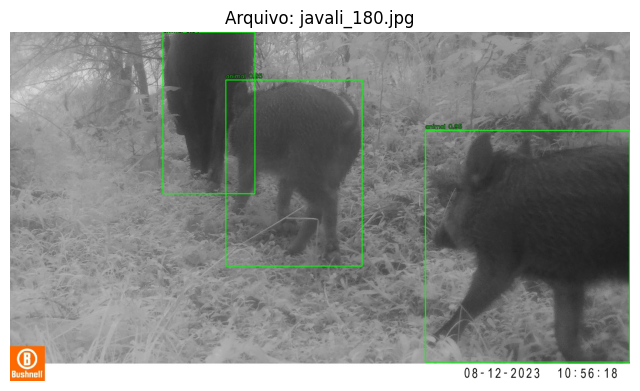

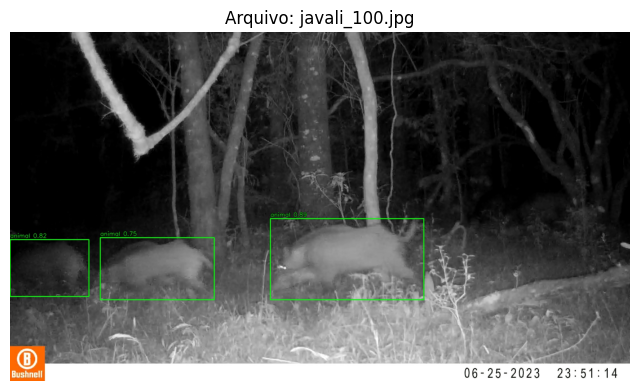

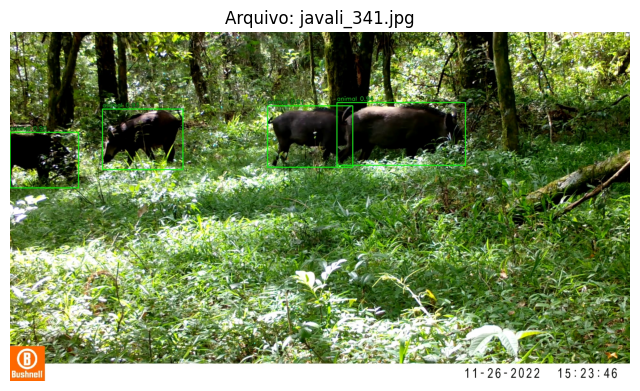

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import glob

image_paths = glob.glob("/content/teste/annotated_images/*.jpg") + glob.glob("/content/teste/img/*.png")

for path in image_paths:
    img = Image.open(path)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.title(f"Arquivo: {path.split('/')[-1]}")
    plt.axis("off")
    plt.show()

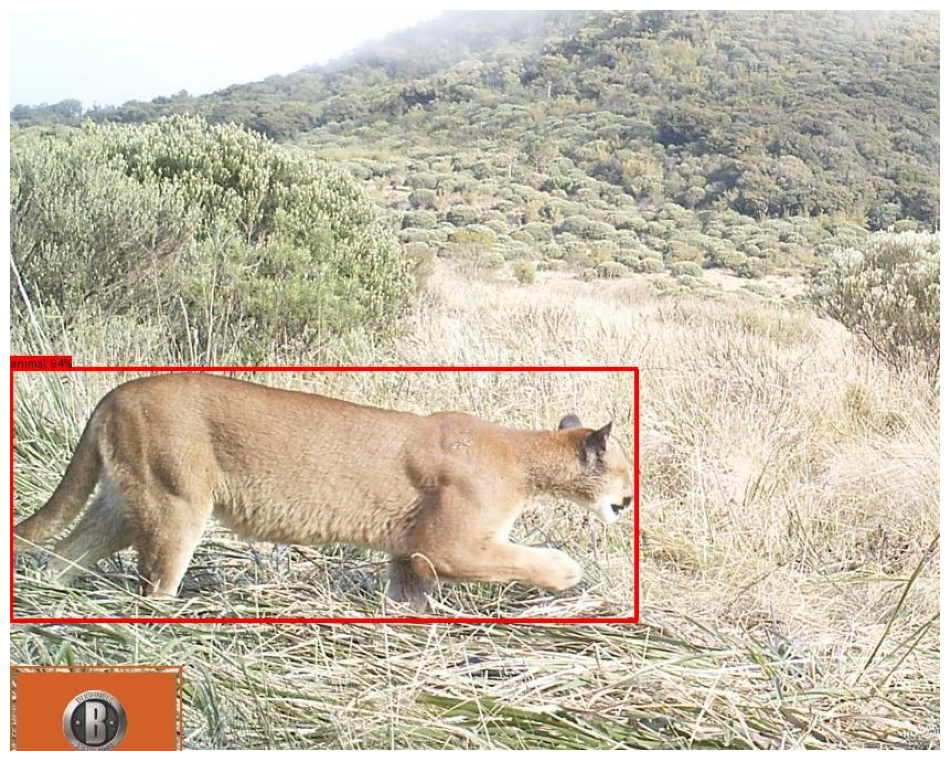

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = "/content/puma.jpg"

img = Image.open(image_path)
plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
import os, json, cv2


json_path  = "..."
video_path = "..."
out_path   = "..."
min_conf   = 0.05

os.makedirs(os.path.dirname(out_path), exist_ok=True)

# ---- JSON (format: images[0].detections with frame_number) ----
with open(json_path, "r") as f:
    jd = json.load(f)

imgs = jd.get("images", [])
if not imgs or "detections" not in imgs[0]:
    raise RuntimeError("JSON inesperado: esperado images[0].detections com frame_number.")

det_list = imgs[0]["detections"]
frame_rate_json = imgs[0].get("frame_rate", None)
cat_map = jd.get("detection_categories", {"1":"animal","2":"person","3":"vehicle"})

# frame_idx -> [det, ...]
frame_map = {}
for d in det_list:
    conf = float(d.get("conf", d.get("confidence", d.get("score", 0))))
    if conf < min_conf:
        continue
    fi = int(d["frame_number"])
    frame_map.setdefault(fi, []).append(d)

# ---- writer ----
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Falha ao abrir vídeo: {video_path}")

W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
if not fps or fps <= 0:
    fps = frame_rate_json or 25.0

def bbox_to_abs(bbox, W, H):
    x, y, w, h = bbox
    if max(x, y, w, h) <= 1.0:
        return int(x*W), int(y*H), int(w*W), int(h*H)
    return int(x), int(y), int(w), int(h)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(out_path, fourcc, fps, (W, H))
if not writer.isOpened():
    # fallback AVI/MJPG
    alt = os.path.splitext(out_path)[0] + ".avi"
    writer = cv2.VideoWriter(alt, cv2.VideoWriter_fourcc(*"MJPG"), fps, (W, H))
    if not writer.isOpened():
        raise RuntimeError("Falha ao abrir VideoWriter (tente outro caminho/codec).")
    out_path = alt
    print(f" MP4 indisponível; salvando em AVI/MJPG: {out_path}")

# ---- render ----
drawn = 0
frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    for d in frame_map.get(frame_idx, []):
        X, Y, WW, HH = bbox_to_abs(d["bbox"], W, H)
        cv2.rectangle(frame, (X, Y), (X+WW, Y+HH), (0,255,0), 2)
        cat = cat_map.get(str(d.get("category","1")), "obj")
        conf = float(d.get("conf", d.get("confidence", d.get("score", 0))))
        cv2.putText(frame, f"{cat} {conf:.2f}", (X, max(0, Y-6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2, cv2.LINE_AA)
        drawn += 1
    writer.write(frame)
    frame_idx += 1

cap.release()
writer.release()
print(f" Generated: {out_path} | Bounding boxes: {drawn} | Frames: {frame_idx}")


In [ ]:
from IPython.display import HTML
from base64 import b64encode
import os
import subprocess
# Input video path
save_path = '...'

# Compressed video path
compressed_path = "..."

subprocess.run([
    'ffmpeg','-y','-i', save_path,
    '-c:v','libx264','-crf','23','-preset','veryfast',
    '-c:a','aac','-b:a','128k',
    '-movflags','+faststart','-pix_fmt','yuv420p',
    compressed_path
], check=True)

with open(compressed_path, 'rb') as f:
    mp4 = f.read()

data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f"""
<video width="800" controls>
  <source src="{data_url}" type="video/mp4">
</video>
""")

# **Using YOLO11 Custom: Step-by-Step Instructions**

A custom YOLO11 model was used for species-level classification. YOLO11, developed by Ultralytics, is a modern object detection architecture that combines accuracy, speed, and efficiency.

For more information, see the official documentation:[Ultralytics YOLO11](https://docs.ultralytics.com/pt/models/yolo11/)


The model was trained with images from the Mixed Ombrophilous Forest (Araucaria Forest) and from areas of dense Araucaria forest, both within the Atlantic Forest biome.

In [ ]:
!pip install ultralytics

In [ ]:
import ultralytics
from ultralytics import YOLO

In [ ]:
ultralytics.checks()

The structure shown below can point either to a folder of images or to a single image file.
The same logic applies to videos: it can represent a folder of videos or a single video file.

In [ ]:
MODEL_PATH = "caminho/weights/best.pt"  # Model path
DATA_IMAGES_DIR = ".../"
DATA_VIDEOS_DIR = ".../"

In [ ]:
model = YOLO(MODEL_PATH)
print("Model-mapped classe:", model.names)

In [ ]:
from PIL import Image
import IPython.display as display
import os
#processing image
results = model.predict(source=DATA_IMAGES_DIR,save_json=True, save=True, save_txt= True)


out_dir = results[0].save_dir

#Builds the path of the annotated image (same name as the input inside the folder)
out_path = os.path.join(out_dir, os.path.basename(DATA_IMAGES_DIR))



In [ ]:
#temporario
from PIL import Image
import IPython.display as display
import os


custom_out_dir = "..."

os.makedirs(custom_out_dir, exist_ok=True)

results = model.predict(
    source=DATA_IMAGES_DIR,
    save_json=True,
    save=True,
    save_txt=True,
    project=custom_out_dir,
    name="resultados02_teste"
)

out_dir = results[0].save_dir
out_path = os.path.join(out_dir, os.path.basename(DATA_IMAGES_DIR))

print(f"✅ Resultados salvos em: {out_dir}")


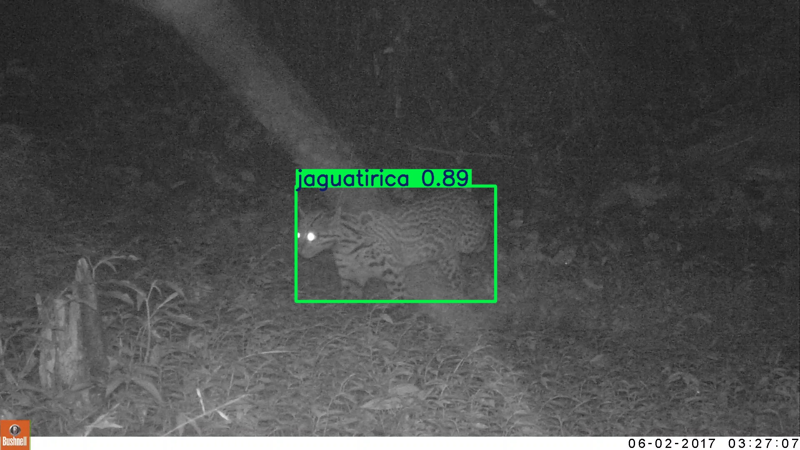

In [ ]:
# Resizes the image before displaying
img = Image.open(out_path)
img_resized = img.resize((800, int(img.height * 800 / img.width)))

display.display(img_resized)

In [ ]:
#processing video
results = model.predict(source=DATA_VIDEOS_DIR, save=True)

In [ ]:
from IPython.display import HTML
from base64 import b64encode
import os
import subprocess
# Input video path
save_path = '.../'

# Compressed video path
compressed_path = ".../"

subprocess.run([
    'ffmpeg','-y','-i', save_path,
    '-c:v','libx264','-crf','23','-preset','veryfast',
    '-c:a','aac','-b:a','128k',
    '-movflags','+faststart','-pix_fmt','yuv420p',
    compressed_path
], check=True)

with open(compressed_path, 'rb') as f:
    mp4 = f.read()

data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f"""
<video width="800" controls>
  <source src="{data_url}" type="video/mp4">
</video>
""")

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import glob

image_paths = glob.glob("/content/teste/annotated_images/*.jpg") + glob.glob("/content/teste/img/*.png")

for path in image_paths:
    img = Image.open(path)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.title(f"Arquivo: {path.split('/')[-1]}")
    plt.axis("off")
    plt.show()